# Home Credit : scoring du risque de défaut de crédit
## Notebook 02 : nettoyage et modèles de référence

Ce notebook applique les règles établies lors de l'exploration, puis construit deux modèles de référence sur la seule table principale :

1. une **régression logistique** classique (variables standardisées, encodage one-hot) ;
2. une **grille de score** (*scorecard*), le format historique des banques : chaque variable est découpée en classes, chaque classe rapporte un nombre de points, et le score du client est la somme de ses points.

Ces références serviront d'étalon : les tables secondaires (notebook 03) et les modèles plus complexes (notebook 04) devront faire mieux qu'elles.

**L'échantillon de test n'est pas utilisé ici.** Toutes les performances sont mesurées par validation croisée sur l'échantillon d'apprentissage. Le test reste intact pour l'évaluation finale.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import roc_auc_score, roc_curve, brier_score_loss
from sklearn.calibration import calibration_curve

sys.path.append(str(Path("..").resolve()))
from src.preparation import nettoyer, Ecreteur, EncodeurWoE, LogistiqueSignesCoherents, VARIABLES_EQUITE

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

GRAINE = 42
DOSSIER_BRUTES = Path("../data/brutes")
DOSSIER_TRAITEES = Path("../data/traitees")

# 1. Application des règles de nettoyage

Les règles fixes sont regroupées dans la fonction `nettoyer` du module `src/preparation.py`, pour être réutilisées à l'identique dans tous les notebooks (et plus tard dans une application). Comme elles ne dépendent pas des données (pas de moyenne, pas de centile), on peut les appliquer à toute la base sans risque de fuite.

In [2]:
brut = pd.read_csv(DOSSIER_BRUTES / "application_train.csv")
propre = nettoyer(brut)
decoupage = pd.read_csv(DOSSIER_TRAITEES / "decoupage.csv")
propre = propre.merge(decoupage, on="SK_ID_CURR", how="left", validate="one_to_one")

print(f"Avant : {brut.shape[1]} colonnes   Après : {propre.shape[1]} colonnes")
print(propre["echantillon"].value_counts())

Avant : 122 colonnes   Après : 83 colonnes
echantillon
apprentissage    246008
test              61503
Name: count, dtype: int64


## Vérification des règles

In [3]:
controles = pd.Series({
    "Code 365243 restant dans DAYS_EMPLOYED": int((brut["DAYS_EMPLOYED"] == 365243).sum() - propre["SANS_EMPLOI"].sum()),
    "Clients sans emploi (indicatrice)": int(propre["SANS_EMPLOI"].sum()),
    "Ancienneté d'emploi maximale (ans)": round(propre["ANCIENNETE_EMPLOI"].max(), 1),
    "Âge minimal / maximal (ans)": f"{propre['AGE'].min():.1f} / {propre['AGE'].max():.1f}",
    "Modalité XNA restante (sexe)": int((propre["CODE_GENDER"] == "XNA").sum()),
    "Retraités avec profession « Retraité »": int((propre["OCCUPATION_TYPE"] == "Retraité").sum()),
    "Professions non renseignées (hors retraités)": int((propre["OCCUPATION_TYPE"] == "Non renseignée").sum()),
    "Variables d'immeuble restantes": sum(c.endswith("_AVG") for c in propre.columns) + 1,
    "Documents : variables restantes": sum(c.startswith("FLAG_DOCUMENT") for c in propre.columns) + 1,
})
controles.to_frame("valeur")

,valeur
Code 365243 restant dans DAYS_EMPLOYED,0
Clients sans emploi (indicatrice),55374
Ancienneté d'emploi maximale (ans),49.0
Âge minimal / maximal (ans),20.5 / 69.1
Modalité XNA restante (sexe),0
Retraités avec profession « Retraité »,55357
Professions non renseignées (hors retraités),41034
Variables d'immeuble restantes,15
Documents : variables restantes,2


In [4]:
nouvelles = ["SANS_EMPLOI", "MOYENNE_EXT", "MIN_EXT", "NB_EXT_MANQUANTS", "PART_FINANCEE", "DUREE_ANNUITES",
             "TAUX_EFFORT", "CREDIT_REVENU", "REVENU_PAR_PERSONNE", "ANCIENNETE_SUR_AGE",
             "NB_INFOS_IMMEUBLE_MANQUANTES", "NB_AUTRES_DOCUMENTS"]
propre[nouvelles].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
SANS_EMPLOI,307511.0,0.180,0.384,0.000,0.000,0.000,0.000,1.000000e+00
MOYENNE_EXT,307339.0,0.509,0.150,0.000,0.414,0.525,0.623,8.790000e-01
MIN_EXT,307339.0,0.400,0.187,0.000,0.254,0.403,0.553,8.790000e-01
NB_EXT_MANQUANTS,307511.0,0.764,0.650,0.000,0.000,1.000,1.000,3.000000e+00
PART_FINANCEE,307233.0,1.123,0.124,0.150,1.000,1.119,1.198,6.000000e+00
DUREE_ANNUITES,307499.0,21.612,7.824,8.037,15.614,20.000,27.100,4.530500e+01
TAUX_EFFORT,307499.0,0.181,0.095,0.000,0.115,0.163,0.229,1.876000e+00
CREDIT_REVENU,307511.0,3.958,2.690,0.005,2.019,3.265,5.160,8.473700e+01
REVENU_PAR_PERSONNE,307509.0,93105.880,101373.363,2812.500,47250.000,75000.000,112500.000,3.900000e+07
ANCIENNETE_SUR_AGE,252137.0,0.157,0.134,-0.000,0.056,0.119,0.219,7.290000e-01


In [5]:
propre.to_parquet(DOSSIER_TRAITEES / "application_propre.parquet", index=False)
print("Table nettoyée enregistrée :", DOSSIER_TRAITEES / "application_propre.parquet")

Table nettoyée enregistrée : ../data/traitees/application_propre.parquet


# 2. Variables du modèle

`CODE_GENDER` et `NAME_FAMILY_STATUS` sont **exclues** du modèle pour des raisons d'équité, mais conservées dans la table pour l'audit final.

In [6]:
app = propre[propre["echantillon"] == "apprentissage"].reset_index(drop=True)
y = app["TARGET"]

exclues = ["SK_ID_CURR", "TARGET", "echantillon"] + VARIABLES_EQUITE
qualitatives = [c for c in app.columns if c not in exclues and app[c].dtype.kind not in "biuf"]
numeriques = [c for c in app.columns if c not in exclues and c not in qualitatives]
X = app[numeriques + qualitatives]

print(f"{len(numeriques)} variables numériques, {len(qualitatives)} variables qualitatives")
print("Qualitatives :", qualitatives)

69 variables numériques, 9 variables qualitatives
Qualitatives : ['NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'WEEKDAY_APPR_PROCESS_START', 'ORGANIZATION_TYPE', 'HOUSETYPE_MODE', 'WALLSMATERIAL_MODE']


# 3. Régression logistique

## 3.1 Pipeline

Chaque étape qui apprend quelque chose sur les données est placée dans le pipeline. Pendant la validation croisée, elle est réapprise sur chaque pli, sans jamais voir le pli de validation :

| Étape | Variables | Ce qui est appris |
|---|---|---|
| Écrêtage aux centiles 0,1 % et 99,9 % | numériques | les bornes |
| Imputation par la médiane + indicatrices de manque | numériques | les médianes |
| Standardisation | numériques | moyennes et écarts-types |
| Imputation « manquant » + encodage one-hot (modalités < 0,5 % regroupées) | qualitatives | les modalités |
| Régression logistique pénalisée (L2) | toutes | les coefficients |

In [7]:
def pipeline_logistique(C=0.1, poids=None, numeriques=numeriques, qualitatives=qualitatives):
    pre = ColumnTransformer([
        ("num", Pipeline([("ecretage", Ecreteur()),
                          ("imputation", SimpleImputer(strategy="median", add_indicator=True)),
                          ("standardisation", StandardScaler())]), numeriques),
        ("qual", Pipeline([("imputation", SimpleImputer(strategy="constant", fill_value="manquant")),
                           ("encodage", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.005))]),
         qualitatives),
    ])
    return Pipeline([("preparation", pre),
                     ("modele", LogisticRegression(C=C, class_weight=poids, max_iter=3000))])


validation = StratifiedKFold(n_splits=5, shuffle=True, random_state=GRAINE)
metriques = {"auc": "roc_auc", "auc_pr": "average_precision", "brier": "neg_brier_score"}


def evaluer(modele, X_eval, nom):
    r = cross_validate(modele, X_eval, y, cv=validation, scoring=metriques, n_jobs=-1)
    return {"modèle": nom, "AUC": r["test_auc"].mean(), "écart-type AUC": r["test_auc"].std(),
            "Gini": 2 * r["test_auc"].mean() - 1, "AUC PR": r["test_auc_pr"].mean(),
            "Brier": -r["test_brier"].mean()}

## 3.2 Références simples

Avant de juger la régression logistique complète, on situe deux références :
- un modèle **sans information** (prédit le taux moyen pour tout le monde) ;
- une logistique sur la **seule moyenne des scores externes**, la meilleure variable de l'exploration. C'est ce que ferait un analyste qui se contenterait du score du bureau de crédit.

In [8]:
resultats = [evaluer(DummyClassifier(strategy="prior"), X, "Sans information")]
resultats.append(evaluer(pipeline_logistique(numeriques=["MOYENNE_EXT", "NB_EXT_MANQUANTS"], qualitatives=[]),
                         X, "Logistique : scores externes seuls"))
pd.DataFrame(resultats).round(4)

,modèle,AUC,écart-type AUC,Gini,AUC PR,Brier
0,Sans information,0.5000,0.0000,0.0000,0.0807,0.0742
1,Logistique : scores externes seuls,0.7167,0.0022,0.4334,0.1882,0.0703


## 3.3 Force de la pénalisation

Le paramètre `C` est l'inverse de la force de la pénalisation L2 : plus il est petit, plus les coefficients sont contraints vers zéro.

In [9]:
grille_C = []
for C in [0.001, 0.01, 0.1]:
    grille_C.append(evaluer(pipeline_logistique(C=C), X, f"C = {C}") | {"C": C})
grille_C = pd.DataFrame(grille_C)
grille_C.round(4)

,modèle,AUC,écart-type AUC,Gini,AUC PR,Brier,C
0,C = 0.001,0.7461,0.0014,0.4923,0.2265,0.0686,0.001
1,C = 0.01,0.7471,0.0012,0.4941,0.2271,0.0686,0.010
2,C = 0.1,0.7470,0.0013,0.4940,0.2266,0.0686,0.100


In [10]:
C_retenu = float(grille_C.loc[grille_C["AUC"].idxmax(), "C"])
print(f"C retenu : {C_retenu}")
resultats.append(grille_C.loc[grille_C["C"] == C_retenu].iloc[0].drop("C").to_dict() | {"modèle": "Logistique complète"})

C retenu : 0.01


**Lecture.** La performance est pratiquement insensible à la pénalisation (AUC comprise entre 0,746 et 0,747). Avec 197 000 demandes par pli pour environ 200 coefficients, le modèle a largement assez de données : le risque de surapprentissage est faible, et la pénalisation ne change presque rien. On retient C = 0,01.

Le modèle complet atteint une **AUC de 0,747 (Gini de 0,49)**, contre 0,717 avec les seuls scores externes. Les informations propres à Home Credit (emploi, profession, crédit demandé, région…) ajoutent donc 3 points d'AUC au score du bureau de crédit. La stabilité entre plis est excellente (écart-type de 0,001).

## 3.4 Faut-il rééquilibrer les classes ?

Une pratique répandue consiste à pondérer les défauts pour compenser leur rareté (`class_weight="balanced"`). On compare.

In [11]:
equilibre = evaluer(pipeline_logistique(C=C_retenu, poids="balanced"), X, "Logistique complète, classes pondérées")
pd.DataFrame([resultats[-1], equilibre]).round(4)

,modèle,AUC,écart-type AUC,Gini,AUC PR,Brier
0,Logistique complète,0.7471,0.0012,0.4941,0.2271,0.0686
1,"Logistique complète, classes pondérées",0.7470,0.0012,0.4940,0.2258,0.2034


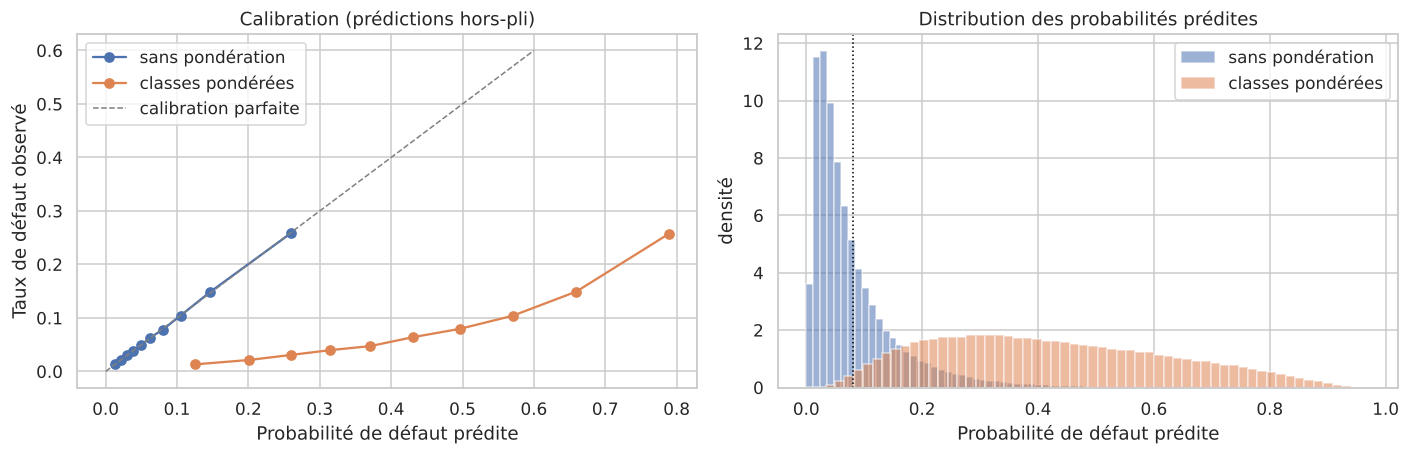

Probabilité moyenne prédite : 0.081 (sans pondération), 0.422 (pondérée) ; taux réel : 0.081


In [12]:
proba_normale = cross_val_predict(pipeline_logistique(C=C_retenu), X, y, cv=validation, method="predict_proba", n_jobs=-1)[:, 1]
proba_ponderee = cross_val_predict(pipeline_logistique(C=C_retenu, poids="balanced"), X, y, cv=validation,
                                   method="predict_proba", n_jobs=-1)[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
for proba, nom, couleur in [(proba_normale, "sans pondération", "#4C72B0"), (proba_ponderee, "classes pondérées", "#DD8452")]:
    frac, moy = calibration_curve(y, proba, n_bins=10, strategy="quantile")
    axes[0].plot(moy, frac, marker="o", color=couleur, label=nom)
    axes[1].hist(proba, bins=60, alpha=0.55, color=couleur, label=nom, density=True)
axes[0].plot([0, 0.6], [0, 0.6], ls="--", color="grey", lw=1, label="calibration parfaite")
axes[0].set(xlabel="Probabilité de défaut prédite", ylabel="Taux de défaut observé", title="Calibration (prédictions hors-pli)")
axes[0].legend()
axes[1].axvline(y.mean(), color="black", ls=":", lw=1)
axes[1].set(xlabel="Probabilité de défaut prédite", ylabel="densité", title="Distribution des probabilités prédites")
axes[1].legend()
plt.tight_layout()
plt.show()

print(f"Probabilité moyenne prédite : {proba_normale.mean():.3f} (sans pondération), "
      f"{proba_ponderee.mean():.3f} (pondérée) ; taux réel : {y.mean():.3f}")

**Lecture.** La pondération des classes ne change **rien au classement** des clients (AUC identique : 0,747) mais **détruit la calibration**. La probabilité moyenne prédite passe à 42 % pour un taux réel de 8 %, et le score de Brier triple (de 0,069 à 0,203). Sur la courbe de calibration, quand le modèle pondéré annonce 50 % de risque, seuls 8 % des clients font réellement défaut.

Pour une banque, la probabilité de défaut n'est pas qu'un outil de classement. Elle sert à calculer la perte attendue, à fixer le prix du crédit et à provisionner, d'où l'importance de sa calibration. **On ne pondère donc pas les classes.** Le déséquilibre sera traité au moment de choisir le seuil d'octroi, en fonction des coûts.

## 3.5 Lecture des coefficients

Les variables numériques étant standardisées, la taille des coefficients est comparable : un coefficient de 0,3 signifie qu'une hausse d'un écart-type multiplie la cote de défaut par $e^{0,3} \approx 1,35$.

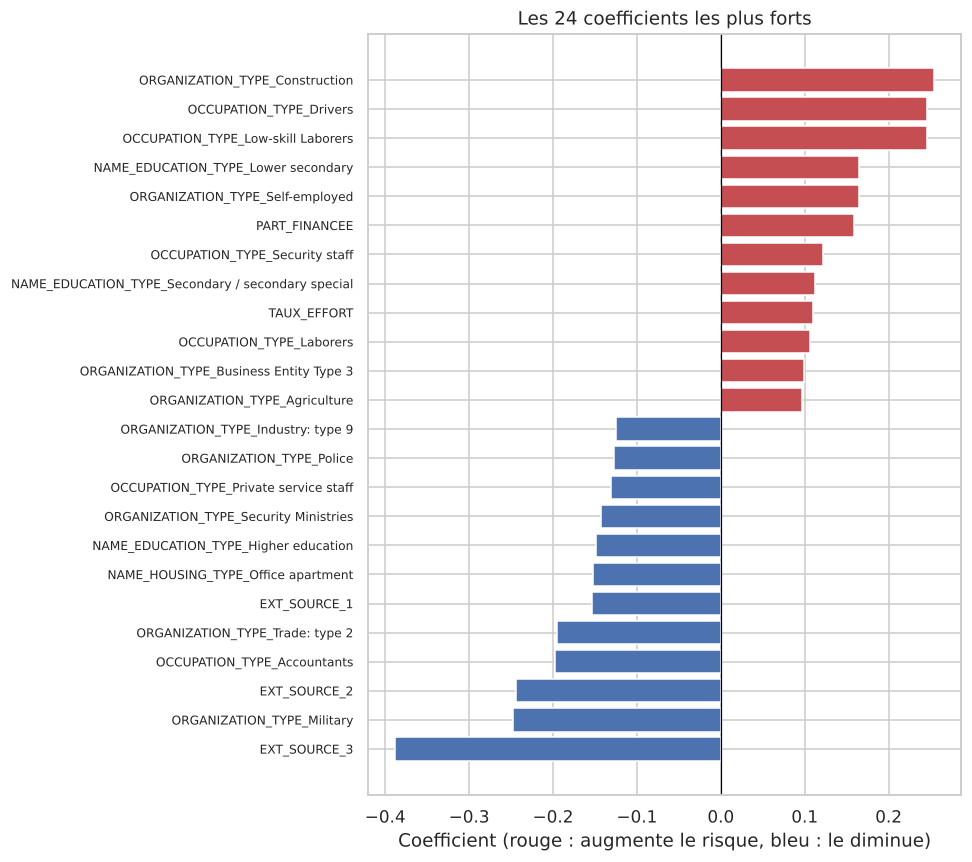

In [13]:
modele_logit = pipeline_logistique(C=C_retenu).fit(X, y)
noms = modele_logit.named_steps["preparation"].get_feature_names_out()
coefficients = pd.Series(modele_logit.named_steps["modele"].coef_[0], index=noms)
coefficients.index = coefficients.index.str.replace("num__", "").str.replace("qual__", "")

top = pd.concat([coefficients.nsmallest(12), coefficients.nlargest(12)]).sort_values()
fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(top.index, top.values, color=np.where(top.values > 0, "#C44E52", "#4C72B0"))
ax.axvline(0, color="black", lw=0.8)
ax.set(xlabel="Coefficient (rouge : augmente le risque, bleu : le diminue)", title="Les 24 coefficients les plus forts")
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

**Lecture.** Les signes sont cohérents avec l'exploration :
- **Facteurs de risque (en rouge) :** certains secteurs (bâtiment, travailleurs indépendants, agriculture) et métiers (chauffeurs, ouvriers peu qualifiés, agents de sécurité), un niveau d'études faible, une part financée élevée (le prêt couvre plus que le bien) et un taux d'effort élevé.
- **Facteurs protecteurs (en bleu) :** les trois scores externes, avec `EXT_SOURCE_3` en tête, les études supérieures, et des employeurs stables (armée, police, ministères).

Le taux d'effort, presque inutile seul (IV de 0,006), retrouve ici un effet : **à profil égal**, consacrer une plus grande part de son revenu au remboursement augmente le risque. C'est l'intérêt d'un modèle multivarié.

# 4. Grille de score

## 4.1 Principe

Une grille de score transforme le modèle en un barème lisible par un conseiller bancaire :

1. chaque variable est découpée en classes, et chaque classe est remplacée par son **Weight of Evidence** (WoE) ;
2. on ne garde que les variables utiles (IV ≥ 0,02) et non redondantes (corrélation des WoE ≤ 0,7) ;
3. une régression logistique est estimée sur ces WoE, en imposant des **signes cohérents** : une classe plus sûre doit toujours rapporter plus de points. Si la colinéarité entre variables produit un coefficient de mauvais signe, la variable est retirée et le modèle réestimé ;
4. les coefficients sont convertis en **points**.

Les étapes 1 et 2 apprennent des paramètres (classes, WoE, sélection) : elles sont dans le pipeline, donc réapprises sur chaque pli de validation.

In [14]:
variables_grille = numeriques + qualitatives


def pipeline_grille(C=1.0):
    return Pipeline([("woe", EncodeurWoE(nb_classes=10, iv_min=0.02, corr_max=0.7)),
                     ("modele", LogistiqueSignesCoherents(C=C))])


resultats.append(evaluer(pipeline_grille(), X[variables_grille], "Grille de score (WoE + logistique)"))
pd.DataFrame(resultats[-1:]).round(4)

,modèle,AUC,écart-type AUC,Gini,AUC PR,Brier
0,Grille de score (WoE + logistique),0.7439,0.0015,0.4878,0.22,0.0688


In [15]:
grille = pipeline_grille().fit(X[variables_grille], y)
woe, logit = grille.named_steps["woe"], grille.named_steps["modele"]
retenues = logit.colonnes_
print(f"Après le filtre IV et corrélation : {len(woe.retenues_)} variables sur {len(variables_grille)}")
print(f"Retirées pour signe incohérent : {logit.retirees_}")
print(f"Variables de la grille finale : {len(retenues)}")
pd.DataFrame({"IV": [woe.iv_[v] for v in retenues], "coefficient": logit.coef_}, index=retenues).round(3)

Après le filtre IV et corrélation : 23 variables sur 78
Retirées pour signe incohérent : ['AGE', 'NAME_INCOME_TYPE', 'REG_CITY_NOT_WORK_CITY']
Variables de la grille finale : 20


,IV,coefficient
MOYENNE_EXT,0.609,-0.645
EXT_SOURCE_3,0.330,-0.393
EXT_SOURCE_1,0.151,-0.117
DUREE_ANNUITES,0.142,-0.451
ANCIENNETE_EMPLOI,0.112,-0.280
AMT_GOODS_PRICE,0.091,-0.327
OCCUPATION_TYPE,0.089,-0.225
PART_FINANCEE,0.072,-0.439
ORGANIZATION_TYPE,0.060,-0.267
REGION_RATING_CLIENT_W_CITY,0.052,-0.313


**Lecture.** Le filtre sur l'IV et les corrélations ramène les 78 variables à 23. Trois d'entre elles ont ensuite été **retirées pour signe incohérent** : l'âge, le type de revenu et l'indicatrice « ville de résidence différente de la ville de travail ». L'âge est pourtant très lié au risque, mais l'essentiel de son information est déjà porté par les scores externes et l'ancienneté dans l'emploi. Une fois ces variables prises en compte, son coefficient changeait de signe, et la grille aurait donné **moins** de points aux clients âgés, ce qui contredit les données.

La grille finale compte **20 variables**, tous les coefficients sont négatifs (une classe plus sûre rapporte plus de points), et elle reste lisible par un conseiller.

## 4.2 Conversion en points

Convention usuelle : un score de **600 points** correspond à une cote de 50 bons payeurs pour 1 mauvais, et la cote **double tous les 20 points** (*points to double the odds*, PDO). Avec $\text{facteur} = \text{PDO} / \ln 2$ et $\text{décalage} = 600 - \text{facteur} \times \ln 50$, une classe de WoE $w$ d'une variable de coefficient $\beta$ rapporte :

$$\text{points} = \text{facteur} \times \left(\beta \, w + \frac{\beta_0}{p}\right) + \frac{\text{décalage}}{p}$$

où $\beta_0$ est la constante du modèle et $p$ le nombre de variables. Le modèle étant estimé sur la cote de **défaut**, alors que la WoE est définie dans le sens « bon payeur », les signes sont ajustés pour qu'un score élevé signifie un client sûr.

In [16]:
PDO, SCORE_REF, COTE_REF = 20, 600, 50
facteur = PDO / np.log(2)
decalage = SCORE_REF - facteur * np.log(COTE_REF)
beta0, betas = logit.intercept_, dict(zip(retenues, logit.coef_))
p = len(retenues)

lignes = []
for v in retenues:
    for classe, w in woe.woe_[v].items():
        points = facteur * (-betas[v] * w - beta0 / p) + decalage / p
        lignes.append({"variable": v, "classe": classe, "WoE": w, "points": points})
bareme = pd.DataFrame(lignes)
bareme["points"] = bareme["points"].round().astype(int)


def ordre_classe(c):
    if c == "manquant":
        return np.inf
    try:
        return float(c.split(",")[0].strip("([ "))
    except ValueError:
        return 0.0


for v in ["MOYENNE_EXT", "ANCIENNETE_EMPLOI", "NAME_EDUCATION_TYPE"]:
    t = bareme[bareme["variable"] == v].copy()
    t = t.iloc[np.argsort([ordre_classe(c) for c in t["classe"]])] if v != "NAME_EDUCATION_TYPE" else t.sort_values("points")
    print(f"\n{v}")
    print(t[["classe", "WoE", "points"]].round(3).to_string(index=False))


MOYENNE_EXT
        classe    WoE  points
 (-inf, 0.304] -1.220       5
(0.304, 0.384] -0.652      16
(0.384, 0.439] -0.289      22
(0.439, 0.484] -0.004      28
(0.484, 0.524]  0.216      32
(0.524, 0.564]  0.417      36
(0.564, 0.602]  0.726      41
(0.602, 0.644]  0.838      43
(0.644, 0.693]  1.062      48
  (0.693, inf]  1.454      55
      manquant -0.110      26

ANCIENNETE_EMPLOI
          classe    WoE  points
   (-inf, 0.912] -0.346      25
  (0.912, 1.687] -0.402      25
  (1.687, 2.513] -0.337      25
   (2.513, 3.42] -0.269      26
   (3.42, 4.512] -0.173      26
  (4.512, 5.911] -0.046      27
  (5.911, 7.644]  0.069      28
 (7.644, 10.067]  0.161      29
(10.067, 14.617]  0.347      31
   (14.617, inf]  0.627      33
        manquant  0.437      31

NAME_EDUCATION_TYPE
                       classe    WoE  points
              Lower secondary -0.351      22
Secondary / secondary special -0.108      26
            Incomplete higher -0.073      27
             Higher edu

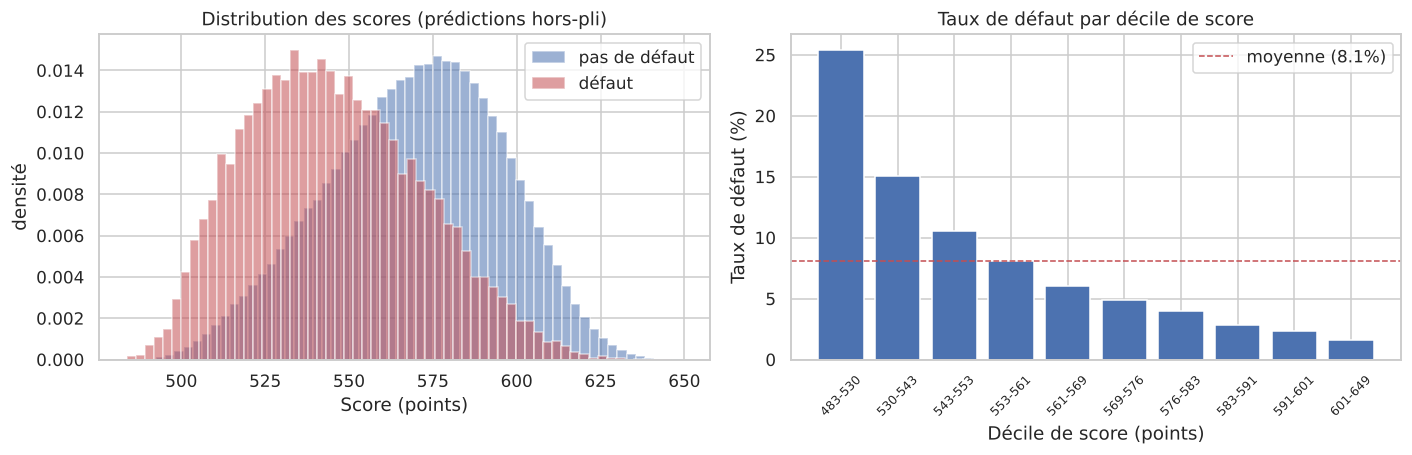

(483.68600000000004, 530.332]    25.40
(530.332, 543.451]               15.03
(543.451, 553.332]               10.55
(553.332, 561.652]                8.10
(561.652, 569.241]                6.07
(569.241, 576.419]                4.90
(576.419, 583.677]                3.95
(583.677, 591.644]                2.80
(591.644, 601.801]                2.35
(601.801, 649.269]                1.57


In [17]:
score_hors_pli = pd.Series(np.nan, index=X.index)
for i_app, i_val in validation.split(X, y):
    g = pipeline_grille().fit(X.iloc[i_app][variables_grille], y.iloc[i_app])
    proba_val = g.predict_proba(X.iloc[i_val][variables_grille])[:, 1]
    score_hors_pli.iloc[i_val] = decalage + facteur * np.log((1 - proba_val) / proba_val)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
for cible, couleur, nom in [(0, "#4C72B0", "pas de défaut"), (1, "#C44E52", "défaut")]:
    axes[0].hist(score_hors_pli[y == cible], bins=60, alpha=0.55, density=True, color=couleur, label=nom)
axes[0].set(xlabel="Score (points)", ylabel="densité", title="Distribution des scores (prédictions hors-pli)")
axes[0].legend()

tranches = pd.qcut(score_hors_pli, 10)
par_tranche = y.groupby(tranches, observed=True).mean() * 100
axes[1].bar([f"{int(i.left)}-{int(i.right)}" for i in par_tranche.index], par_tranche.values, color="#4C72B0")
axes[1].axhline(y.mean() * 100, color="#C44E52", ls="--", lw=1, label=f"moyenne ({y.mean():.1%})")
axes[1].set(xlabel="Décile de score (points)", ylabel="Taux de défaut (%)", title="Taux de défaut par décile de score")
axes[1].tick_params(axis="x", rotation=45, labelsize=8)
axes[1].legend()
plt.tight_layout()
plt.show()

print(par_tranche.round(2).to_string())

**Lecture.**
- **Le barème est lisible :** un client dont la moyenne des scores externes dépasse 0,69 reçoit 55 points pour cette variable, contre 5 en dessous de 0,30. Un diplômé du supérieur reçoit 35 points, contre 22 pour un niveau collège. Le client sans emploi (retraité) reçoit 31 points d'ancienneté, ce qui est cohérent avec son faible risque.
- **Les scores des deux populations sont bien séparés**, même si leurs distributions se recouvrent largement, comme toujours en crédit.
- **Le taux de défaut décroît régulièrement avec le score** : 25,4 % dans le premier décile (moins de 530 points) contre 1,6 % dans le dernier (plus de 602 points), soit un rapport de 1 à 16. C'est cette monotonie qui permet de fixer des règles simples, par exemple « refus en dessous de 530 points, étude manuelle entre 530 et 553 ».

# 5. Bilan des modèles de référence

In [18]:
bilan = pd.DataFrame(resultats).set_index("modèle")
bilan.round(4)

,AUC,écart-type AUC,Gini,AUC PR,Brier
modèle,,,,,
Sans information,0.5000,0.0000,0.0000,0.0807,0.0742
Logistique : scores externes seuls,0.7167,0.0022,0.4334,0.1882,0.0703
Logistique complète,0.7471,0.0012,0.4941,0.2271,0.0686
Grille de score (WoE + logistique),0.7439,0.0015,0.4878,0.2200,0.0688


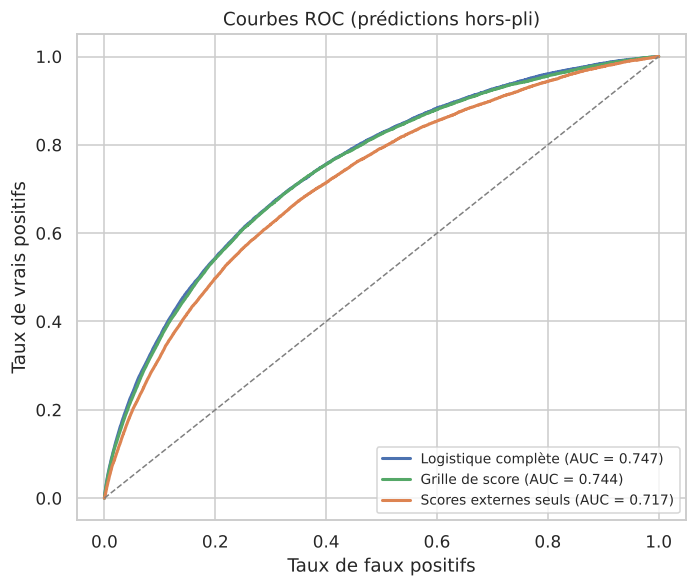

In [19]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
proba_grille = 1 / (1 + np.exp((score_hors_pli - decalage) / facteur))
proba_ext = cross_val_predict(pipeline_logistique(numeriques=["MOYENNE_EXT", "NB_EXT_MANQUANTS"], qualitatives=[]),
                              X, y, cv=validation, method="predict_proba", n_jobs=-1)[:, 1]
for proba, nom, couleur in [(proba_normale, "Logistique complète", "#4C72B0"),
                            (proba_grille, "Grille de score", "#55A868"),
                            (proba_ext, "Scores externes seuls", "#DD8452")]:
    fpr, tpr, _ = roc_curve(y, proba)
    ax.plot(fpr, tpr, lw=2, color=couleur, label=f"{nom} (AUC = {roc_auc_score(y, proba):.3f})")
ax.plot([0, 1], [0, 1], color="grey", ls="--", lw=1)
ax.set(xlabel="Taux de faux positifs", ylabel="Taux de vrais positifs", title="Courbes ROC (prédictions hors-pli)")
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

## Ce que l'on retient

| Modèle | AUC | Gini | Brier |
|---|---|---|---|
| Sans information | 0,500 | 0,000 | 0,0742 |
| Scores externes seuls | 0,717 | 0,433 | 0,0703 |
| **Logistique complète** | **0,747** | **0,494** | **0,0686** |
| Grille de score (20 variables) | 0,744 | 0,488 | 0,0688 |

1. **La référence à battre est une AUC de 0,747** (Gini de 0,49), obtenue avec la seule table principale.
2. **La grille de score ne perd presque rien** (0,744) en n'utilisant que 20 variables, avec un barème de points compréhensible et des signes cohérents. C'est le compromis que choisissent souvent les banques : un peu moins de performance contre beaucoup plus de transparence pour les clients, les conseillers et le régulateur.
3. **Les probabilités sont bien calibrées** sans pondération des classes ; le seuil d'octroi sera fixé plus tard selon les coûts.

## Prochaine étape

Le notebook 03 construira, en **SQL avec DuckDB**, des variables d'historique à partir des six tables secondaires : crédits passés auprès d'autres organismes, demandes antérieures chez Home Credit, retards de paiement, utilisation des cartes de crédit. L'objectif est de mesurer combien ces informations améliorent cette référence de 0,747.